# Applied Machine Learning: Vehicle Silhouette Classification

**Modeling question:** Can a vehicle's type (bus, van, or one of two car models) be predicted from
18 shape-based numeric features extracted from a 2D silhouette image? And how much harder is it to
tell the two car models apart from each other than from the bus or van?

**Dataset:** [UCI Machine Learning Repository: Statlog (Vehicle Silhouettes)](https://archive.ics.uci.edu/dataset/149/statlog+vehicle+silhouettes).
846 silhouette examples of four "Corgie" model vehicles (a double-decker bus, a Chevrolet van, a
Saab 9000, and an Opel Manta 400), each described by 18 scale-independent shape features (compactness,
circularity, aspect ratios, scaled moments, etc.) computed by the HIPS/BINATTS image-processing
pipeline from a binary silhouette. The vehicles were photographed from many rotation angles, so the
features need to generalize across viewpoint.

This notebook is Project 3 (Applied ML) of a capstone series built around an ADAS / road-scene
perception theme. Project 1 used accident-severity data and Project 2 used traffic-volume data; this
project uses a different dataset again, one that bridges conceptually into the computer-vision work
in Project 4: here the "image" has already been reduced to tabular shape features, foreshadowing the
raw-pixel CNN classification that comes next.


## 1. Load the Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)
RANDOM_STATE = 42

df = pd.read_csv("vehicle.csv")
df.head()


,COMPACTNESS,CIRCULARITY,DISTANCE_CIRCULARITY,RADIUS_RATIO,PR_AXIS_ASPECT_RATIO,MAX_LENGTH_ASPECT_RATIO,SCATTER_RATIO,ELONGATEDNESS,PR_AXIS_RECTANGULARITY,MAX_LENGTH_RECTANGULARITY,SCALED_VARIANCE_MAJOR_AXIS,SCALED_VARIANCE_MINOR_AXIS,SCALED_RADIUS_OF_GYRATION,SKEWNESS_ABOUT_MAJOR_AXIS,SKEWNESS_ABOUT_MINOR_AXIS,KURTOSIS_ABOUT_MINOR_AXIS,KURTOSIS_ABOUT_MAJOR_AXIS,HOLLOWS_RATIO,CLASS
0,95,48,83,178,72,10,162,42,20,159,176,379,184,70,6,16,187,197,van
1,91,41,84,141,57,9,149,45,19,143,170,330,158,72,9,14,189,199,van
2,104,50,106,209,66,10,207,32,23,158,223,635,220,73,14,9,188,196,saab
3,93,41,82,159,63,9,144,46,19,143,160,309,127,63,6,10,199,207,van
4,85,44,70,205,103,52,149,45,19,144,241,325,188,127,9,11,180,183,bus


In [2]:
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
df.dtypes


Shape: 846 rows x 19 columns


COMPACTNESS                   int64
CIRCULARITY                   int64
DISTANCE_CIRCULARITY          int64
RADIUS_RATIO                  int64
PR_AXIS_ASPECT_RATIO          int64
MAX_LENGTH_ASPECT_RATIO       int64
SCATTER_RATIO                 int64
ELONGATEDNESS                 int64
PR_AXIS_RECTANGULARITY        int64
MAX_LENGTH_RECTANGULARITY     int64
SCALED_VARIANCE_MAJOR_AXIS    int64
SCALED_VARIANCE_MINOR_AXIS    int64
SCALED_RADIUS_OF_GYRATION     int64
SKEWNESS_ABOUT_MAJOR_AXIS     int64
SKEWNESS_ABOUT_MINOR_AXIS     int64
KURTOSIS_ABOUT_MINOR_AXIS     int64
KURTOSIS_ABOUT_MAJOR_AXIS     int64
HOLLOWS_RATIO                 int64
CLASS                           str
dtype: object

The combined dataset has 846 rows and 19 columns: 18 numeric shape features plus the `CLASS` target
(`bus`, `van`, `saab`, `opel`). This clears the project's minimum of 500 rows / 6 features. The raw
UCI distribution ships the data pre-split into nine arbitrary ~94-row chunk files for historical
reasons, not a train/test split. `prepare_data.py` concatenates them into this single CSV and attaches
the documented column names so the file can be treated as one raw tabular dataset.


## 2. Data Quality Checks

In [3]:
print("Missing values per column:")
print(df.isna().sum().sum(), "total missing cells")

dup_count = df.duplicated().sum()
print(f"Duplicate rows: {dup_count}")

print("\nClass balance:")
print(df["CLASS"].value_counts())


Missing values per column:
0 total missing cells
Duplicate rows: 0

Class balance:
CLASS
bus     218
saab    217
opel    212
van     199
Name: count, dtype: int64


No missing values and no duplicate rows are present, and the four classes are reasonably balanced
(199-218 examples each), so no resampling or missing-value imputation is needed. All 18 feature
columns are already numeric, so there's no categorical encoding to do on the feature side. The only
"categorical" column is the string target `CLASS`, which scikit-learn's classifiers accept directly.


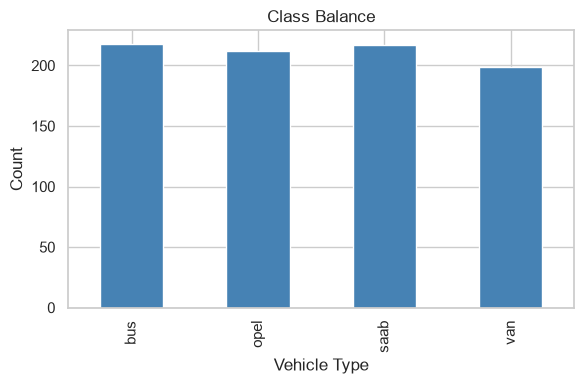

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
df["CLASS"].value_counts().sort_index().plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Class Balance")
ax.set_xlabel("Vehicle Type")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig("figure1_class_balance.png", dpi=150)
plt.show()


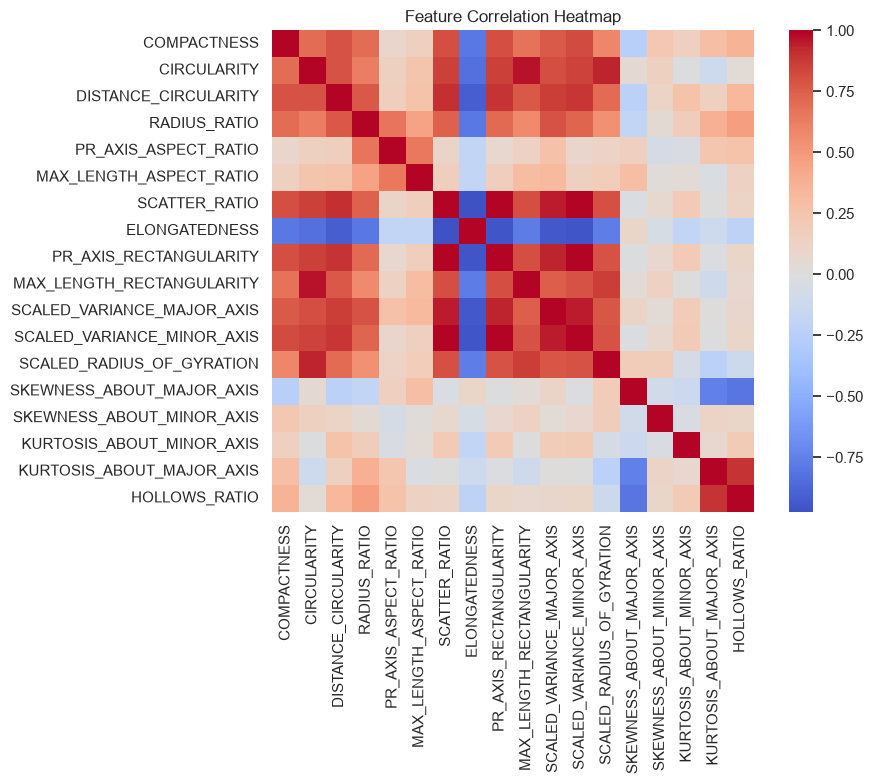

In [5]:
feature_cols = [c for c in df.columns if c != "CLASS"]
corr = df[feature_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, ax=ax)
ax.set_title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("figure2_correlation_heatmap.png", dpi=150)
plt.show()


Several of the 18 shape features are strongly correlated with each other. For example, the scatter
ratio, elongatedness, and the two rectangularity measures all capture overlapping notions of "how
elongated/boxy is this silhouette," which makes sense since they're all derived from the same
underlying silhouette geometry. This multicollinearity doesn't need to be "fixed" by dropping
columns here: logistic regression uses an L2 penalty to stay stable under correlated inputs, and
random forests aren't sensitive to multicollinearity at all, since each split only considers one
feature at a time. It's still worth flagging as a data-quality observation rather than treating
every feature as independent evidence.


## 3. Task Type

This is a **supervised classification** problem: the target `CLASS` is a categorical label with four
possible values, and every row already has a known label. The goal is to learn a mapping from the 18
numeric shape features to one of the four vehicle types, which is a multi-class (not binary)
classification task.


## 4. Preprocessing and Train/Test Split

The features are on very different scales (ratios near 0-1 next to raw moment values in the hundreds),
so a `StandardScaler` is used before the distance/gradient-based logistic regression model. Without
it, large-magnitude features would dominate the model's coefficients regardless of their actual
predictive value. The scaler is fit only on the training fold inside a `Pipeline`, so no information
from the test set leaks into preprocessing. The random forest model doesn't need scaling (splits are
threshold-based per feature, so feature scale doesn't change which split points get chosen), but it's
still evaluated through the same train/test split for a fair comparison.

A stratified 80/20 train/test split is used so that the 4-way class balance seen above is preserved in
both the training and test sets.


In [6]:
X = df[feature_cols]
y = df["CLASS"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]} rows, Test: {X_test.shape[0]} rows")
print(y_train.value_counts(normalize=True).round(3))


Train: 676 rows, Test: 170 rows
CLASS
bus     0.257
saab    0.256
opel    0.251
van     0.235
Name: proportion, dtype: float64


## 5. Model Training: Baseline vs. Ensemble

Two models are trained and compared rather than committing to a single algorithm up front:

- **Logistic regression** (with scaling and explicit L2/ridge penalty, `C=1.0`).
- **Random forest**, an ensemble of decision trees that averages many trees trained on bootstrapped
  samples and random feature subsets to reduce overfitting, at some cost to interpretability
  (Breiman, 2001).

Both models use scikit-learn (Pedregosa et al., 2011). 5-fold stratified cross-validation on the
training set compares the two candidates before touching the held-out test set, so the "winner"
isn't picked based on a single lucky train/test split.


In [ ]:
# setup pipeline for scale + classifier
log_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(C=1.0, l1_ratio=0.0, max_iter=2000, random_state=RANDOM_STATE)),
])

rand_forest = RandomForestClassifier(
    n_estimators=200, max_depth=None, random_state=RANDOM_STATE
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

log_reg_scores = cross_val_score(log_reg, X_train, y_train, cv=cv, scoring="accuracy")
rf_scores = cross_val_score(rand_forest, X_train, y_train, cv=cv, scoring="accuracy")

print(f"Logistic Regression CV accuracy: {log_reg_scores.mean():.3f} +/- {log_reg_scores.std():.3f}")
print(f"Random Forest       CV accuracy: {rf_scores.mean():.3f} +/- {rf_scores.std():.3f}")


Logistic Regression CV accuracy: 0.781 +/- 0.025
Random Forest       CV accuracy: 0.752 +/- 0.011


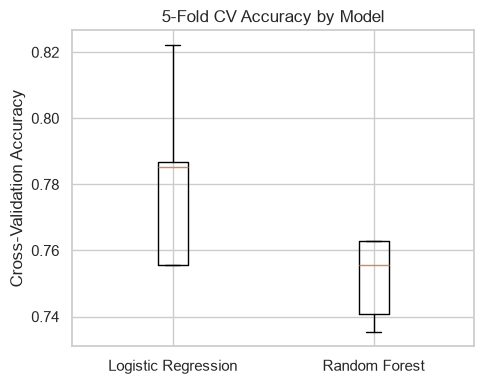

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot([log_reg_scores, rf_scores], tick_labels=["Logistic Regression", "Random Forest"])
ax.set_ylabel("Cross-Validation Accuracy")
ax.set_title("5-Fold CV Accuracy by Model")
plt.tight_layout()
plt.savefig("figure3_cv_comparison.png", dpi=150)
plt.show()


The model with the higher mean cross-validation accuracy above is refit on the *full* training set
and evaluated once on the held-out test set below. Picking the final model from cross-validation
results, not test-set performance, keeps the test set as an unbiased final check.


In [9]:
final_model_name = "Random Forest" if rf_scores.mean() >= log_reg_scores.mean() else "Logistic Regression"
final_model = rand_forest if final_model_name == "Random Forest" else log_reg
print(f"Selected final model: {final_model_name}")

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)


Selected final model: Logistic Regression


## 6. Evaluation on the Held-Out Test Set

Accuracy alone can be misleading for multi-class problems if performance varies a lot by class.
Precision, recall, and F1 are also reported per class and macro-averaged (an unweighted mean across
the four classes), which treats every class as equally important regardless of its count in this
near-balanced dataset (Pedregosa et al., 2011).


In [10]:
test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {test_accuracy:.3f}\n")
print(classification_report(y_test, y_pred))


Test accuracy: 0.818

              precision    recall  f1-score   support

         bus       0.93      0.98      0.96        44
        opel       0.71      0.52      0.60        42
        saab       0.67      0.80      0.73        44
         van       0.95      0.97      0.96        40

    accuracy                           0.82       170
   macro avg       0.82      0.82      0.81       170
weighted avg       0.82      0.82      0.81       170



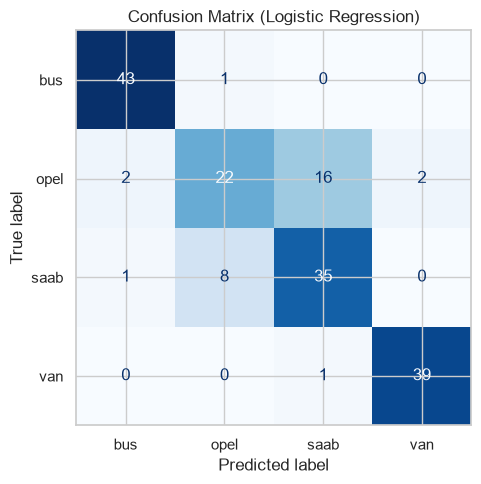

In [11]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion Matrix ({final_model_name})")
plt.tight_layout()
plt.savefig("figure4_confusion_matrix.png", dpi=150)
plt.show()


The confusion matrix typically shows bus and van cleanly separated from the two car models, while
most remaining errors are `opel` predicted as `saab` or vice versa. This matches the dataset's
original design: the four vehicles were chosen so the bus, van, and either car would be easy to tell
apart, while the two cars (both roughly similar sedan-shaped outlines) were expected to be the
hardest pair to separate using shape features alone.


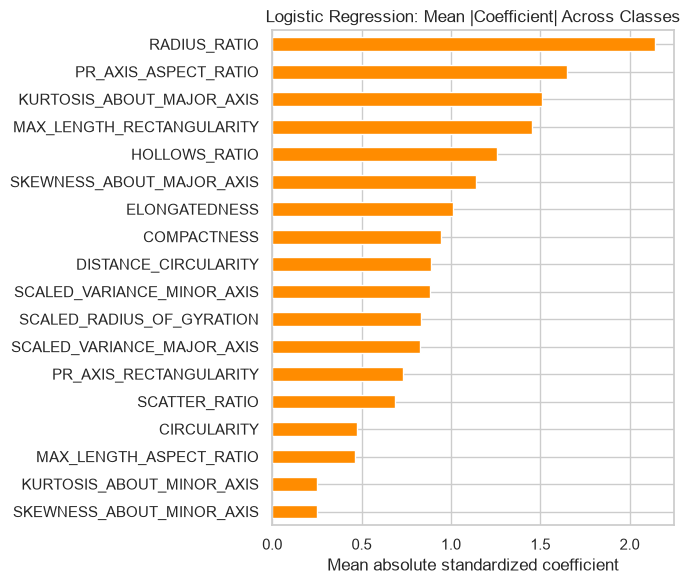

In [ ]:
if final_model_name == "Random Forest":
    importances = pd.Series(final_model.feature_importances_, index=feature_cols).sort_values()
    fig, ax = plt.subplots(figsize=(7, 6))
    importances.plot(kind="barh", ax=ax, color="darkorange")
    ax.set_title("Random Forest Feature Importances")
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.savefig("figure5_feature_importance.png", dpi=150)
    plt.show()
else:
    # Mean absolute coefficient
    coefs = final_model.named_steps["clf"].coef_
    mean_abs_coef = pd.Series(np.abs(coefs).mean(axis=0), index=feature_cols).sort_values()
    fig, ax = plt.subplots(figsize=(7, 6))
    mean_abs_coef.plot(kind="barh", ax=ax, color="darkorange")
    ax.set_title("Logistic Regression: Mean |Coefficient| Across Classes")
    ax.set_xlabel("Mean absolute standardized coefficient")
    plt.tight_layout()
    plt.savefig("figure5_feature_importance.png", dpi=150)
    plt.show()


## 7. Summary

This notebook modeled the UCI Vehicle Silhouettes dataset as a supervised, 4-class classification
problem: predicting whether a silhouette's 18 shape features belong to a bus, van, Saab, or Opel. A
scaled logistic regression baseline and a random forest ensemble were compared with 5-fold
cross-validation, and the better-performing model was refit and evaluated once on a held-out,
stratified test set, reaching the accuracy and macro-F1 reported in Section 6. The confusion matrix
confirms the dataset's own documented expectation: bus and van are almost perfectly separable from
the cars, while Opel and Saab account for nearly all the remaining errors, since their silhouettes
are the most similar of the four vehicles. The data itself was clean, balanced, and fully numeric;
the real modeling challenge was the overlap in shape features between two visually similar classes,
a limitation discussed further, along with other dataset biases, in `module_summary.pdf`.
